In [1]:
import cv2

video_path = "/home/maria/MouseBox/data/ibl_mouse_video/_iblrig_leftCamera.raw.mp4"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Could not open video")

fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"FPS: {fps}")
print(f"Frames: {n_frames:,}")
print(f"Width: {width}")
print(f"Height: {height}")
print(f"Duration: {n_frames / fps / 60:.2f} minutes")

raw_bytes = n_frames * width * height * 3

print(f"Decoded size: {raw_bytes / 1e9:.2f} GB")

cap.release()

FPS: 60.0
Frames: 321,549
Width: 1280
Height: 1024
Duration: 89.32 minutes
Decoded size: 1264.38 GB


(1024, 1280, 3)
uint8


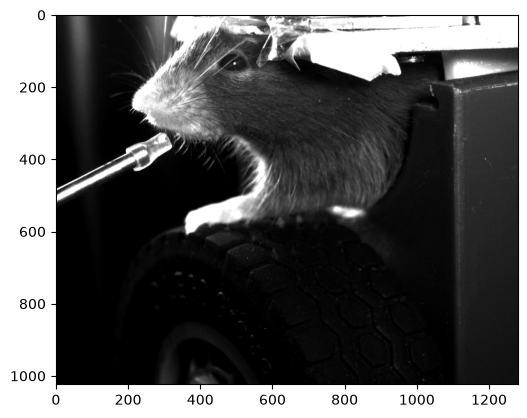

In [3]:
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

seconds = 600

cap.set(cv2.CAP_PROP_POS_FRAMES, int(seconds * fps))

success, frame = cap.read()

if success:
    print(frame.shape)
    print(frame.dtype)
    
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.show()

cap.release()

In [4]:
import cv2


def video_stream(path):
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise RuntimeError("Could not open video")

    try:
        t = 0

        while True:
            success, frame = cap.read()

            if not success:
                break

            yield t, frame

            t += 1

    finally:
        cap.release()

In [5]:
import cv2
import numpy as np

DURATION = 4 * 60
FPS = 60
SAMPLE_FPS = 10

WIDTH = 160
HEIGHT = 128

stride = FPS // SAMPLE_FPS

frames = []

for t, frame in video_stream(video_path):

    if t >= DURATION * FPS:
        break

    if t % stride != 0:
        continue

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    small = cv2.resize(
        gray,
        (WIDTH, HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    frames.append(small.flatten())

X = np.array(frames, dtype=np.float32) / 255.0

print(X.shape)
print(f"Memory: {X.nbytes / 1e6:.2f} MB")

(2400, 20480)
Memory: 196.61 MB


In [6]:
from sklearn.utils.extmath import randomized_svd

mean_frame = X.mean(axis=0)

X_centered = X - mean_frame

U, S, Vt = randomized_svd(
    X_centered,
    n_components=50,
    n_iter=5,
    random_state=42
)

print(U.shape)
print(S.shape)
print(Vt.shape)

(2400, 50)
(50,)
(50, 20480)


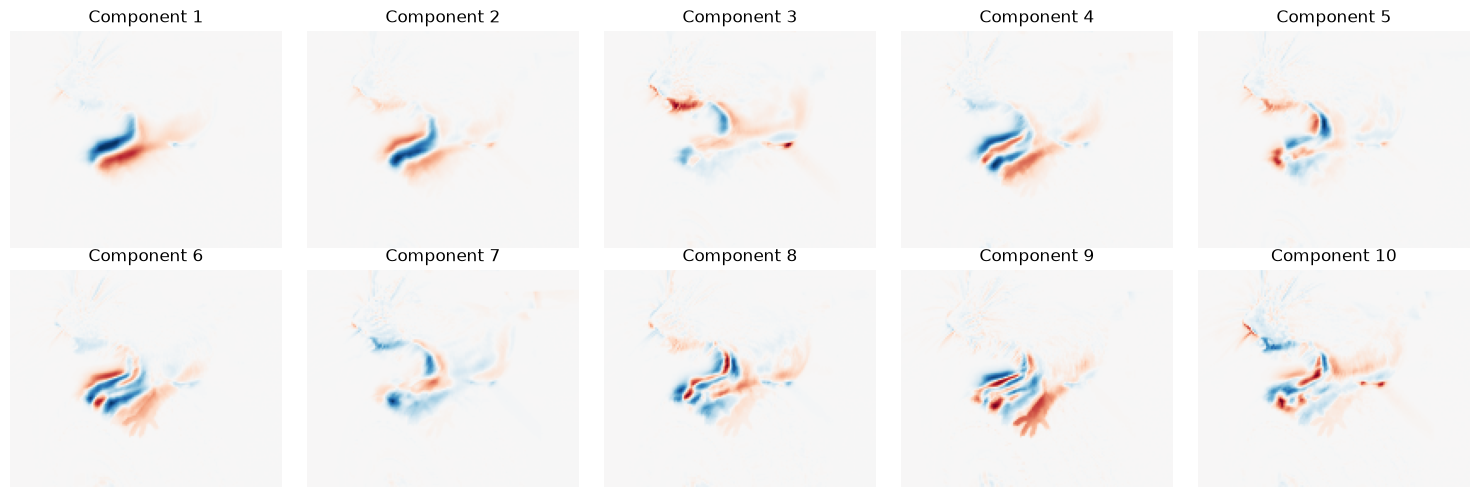

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 5))

for i, ax in enumerate(axes.flat):

    component = Vt[i].reshape(HEIGHT, WIDTH)
    limit = np.abs(component).max()

    ax.imshow(
        component,
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(f"Component {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

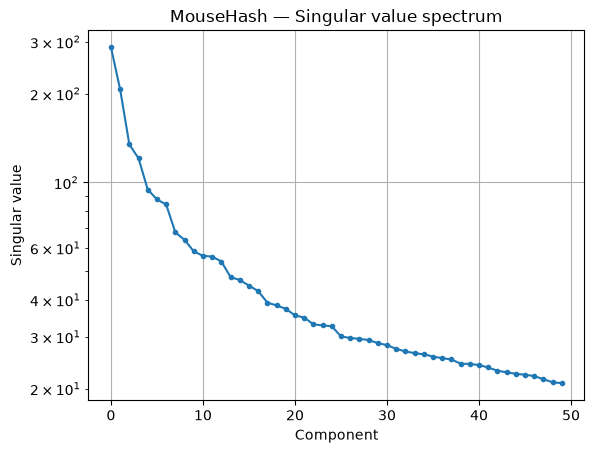

In [8]:
plt.plot(S, marker=".")
plt.yscale("log")
plt.xlabel("Component")
plt.ylabel("Singular value")
plt.title("MouseHash — Singular value spectrum")
plt.grid()
plt.show()

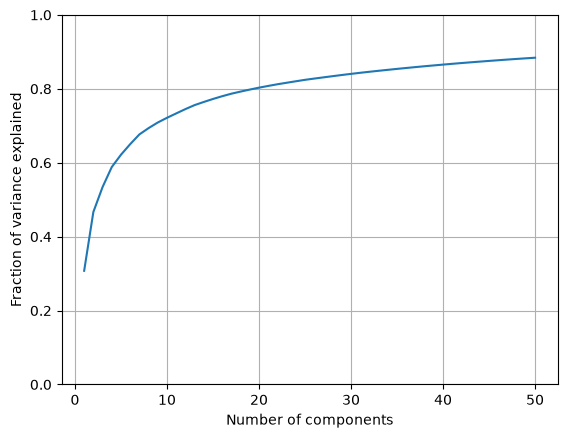

In [9]:
total_variance = np.sum(X_centered ** 2)

explained = np.cumsum(S ** 2) / total_variance

plt.plot(np.arange(1, len(S) + 1), explained)
plt.xlabel("Number of components")
plt.ylabel("Fraction of variance explained")
plt.ylim(0, 1)
plt.grid()
plt.show()

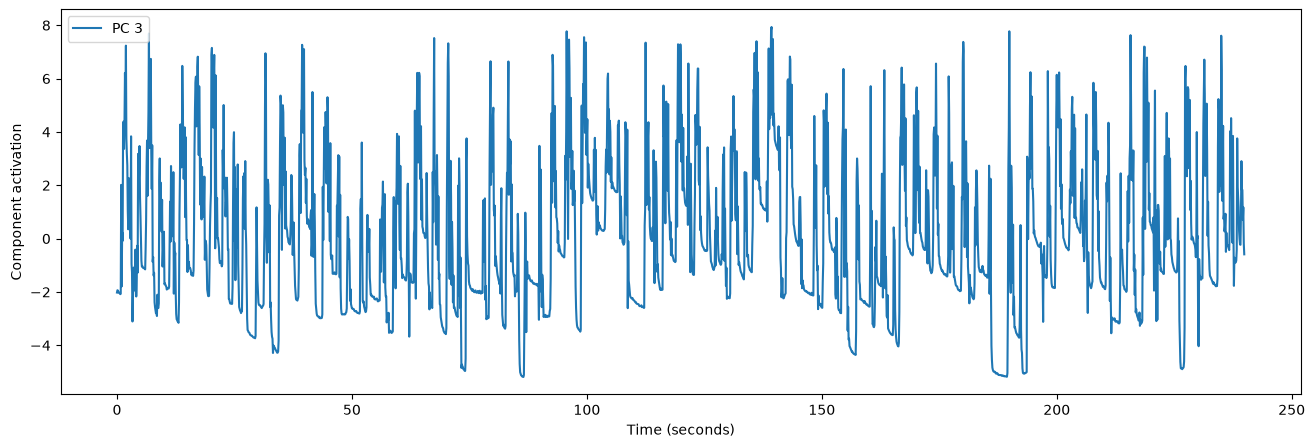

In [13]:
Z = U * S

time = np.arange(len(Z)) / SAMPLE_FPS

plt.figure(figsize=(16, 5))

for i in range(2,3):
    plt.plot(time, Z[:, i], label=f"PC {i + 1}")

plt.xlabel("Time (seconds)")
plt.ylabel("Component activation")
plt.legend()
plt.show()